# LAB 6

## 1. Import the libraries

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import data
from skimage.transform import resize

from numpy.fft import fft2, ifft2, ifftshift

---

## Task 1:

Image shape: (256, 256)


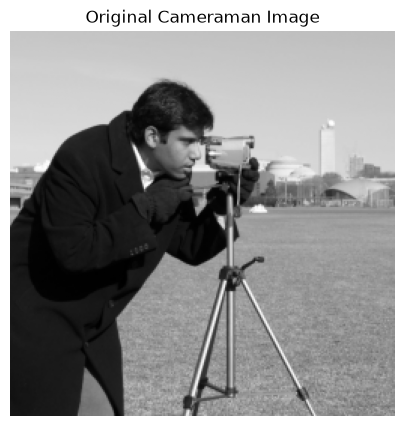

In [3]:
# Load Cameraman image (grayscale)
image = data.camera()

# Resize for faster FFT processing
image = resize(image, (256, 256), anti_aliasing=True)

# Get image dimensions
M, N = image.shape

print("Image shape:", image.shape)

plt.figure(figsize=(5, 5))
plt.imshow(image, cmap="gray")
plt.title("Original Cameraman Image")
plt.axis("off")
plt.show()

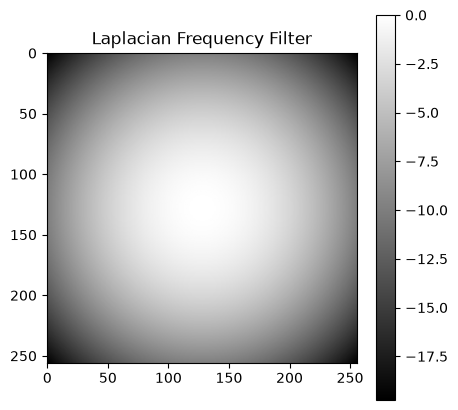

In [4]:
# Generate frequency grid
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Laplacian filter in the frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

plt.figure(figsize=(5, 5))
plt.imshow(np.fft.fftshift(laplacian_filter), cmap="gray")
plt.title("Laplacian Frequency Filter")
plt.colorbar()
plt.show()

In [5]:
# Compute the 2D FFT of the image
F = fft2(image)

# Apply Laplacian filter in the frequency domain
F_lap = F * laplacian_filter

# Inverse FFT to obtain the spatial output
laplacian_image = ifft2(F_lap).real

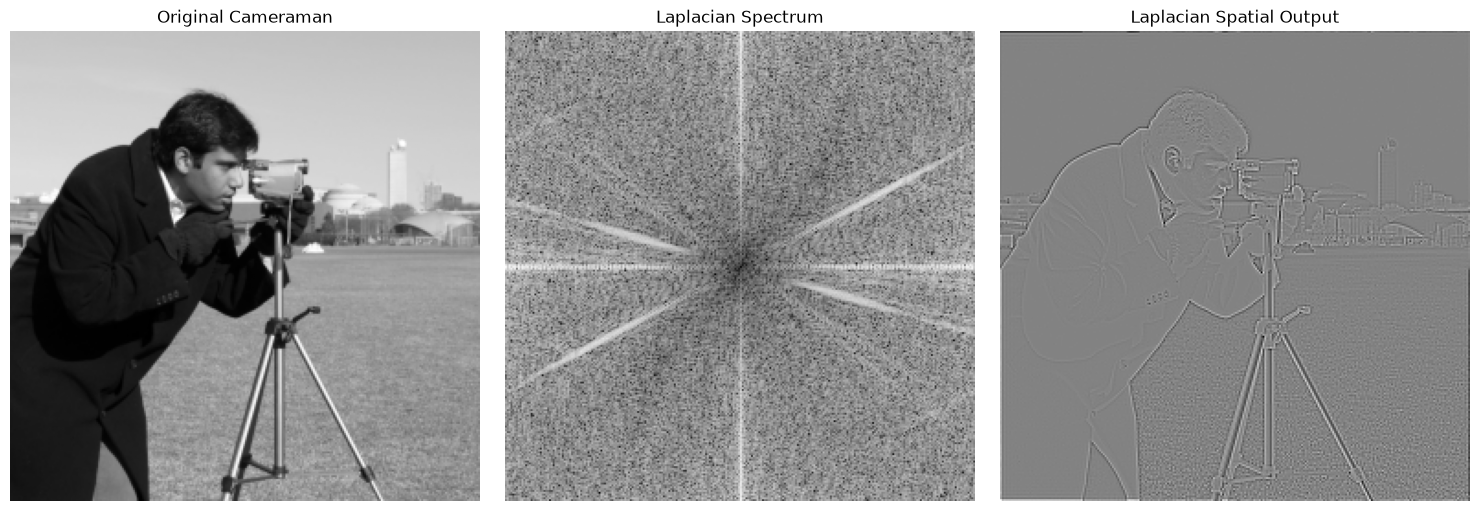

In [6]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Cameraman")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(np.log1p(np.abs(np.fft.fftshift(F_lap))), cmap="gray")
plt.title("Laplacian Spectrum")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap="gray")
plt.title("Laplacian Spatial Output")
plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Sobel X filter
sobel_x = np.array([
    [-1,  0,  1],
    [-2,  0,  2],
    [-1,  0,  1]
], dtype=float)

# Sobel Y filter
sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=float)

print("Sobel X kernel:")
print(sobel_x)

print("\nSobel Y kernel:")
print(sobel_y)

Sobel X kernel:
[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]

Sobel Y kernel:
[[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]


In [8]:
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)

    kh, kw = kernel.shape
    ph, pw = shape

    # Find center coordinates
    cy, cx = ph // 2, pw // 2

    # Insert kernel at the image center
    padded[
        cy - kh // 2:cy - kh // 2 + kh,
        cx - kw // 2:cx - kw // 2 + kw
    ] = kernel

    # Shift the kernel before computing its FFT
    return fft2(ifftshift(padded))


# Compute FFT of the original image
F = fft2(image)

# Compute FFTs of the centered Sobel filters
H_x = center_embed_kernel(sobel_x, image.shape)
H_y = center_embed_kernel(sobel_y, image.shape)

print("Image FFT shape:", F.shape)
print("Sobel X FFT shape:", H_x.shape)
print("Sobel Y FFT shape:", H_y.shape)

Image FFT shape: (256, 256)
Sobel X FFT shape: (256, 256)
Sobel Y FFT shape: (256, 256)


In [9]:
# Multiply in the frequency domain
G_x = F * H_x
G_y = F * H_y

# Apply inverse FFT to obtain spatial outputs
sobel_x_image = ifft2(G_x).real
sobel_y_image = ifft2(G_y).real

# Combine both directions to calculate gradient magnitude
gradient_magnitude = np.sqrt(
    sobel_x_image**2 + sobel_y_image**2
)

print("Sobel filtering completed.")

Sobel filtering completed.


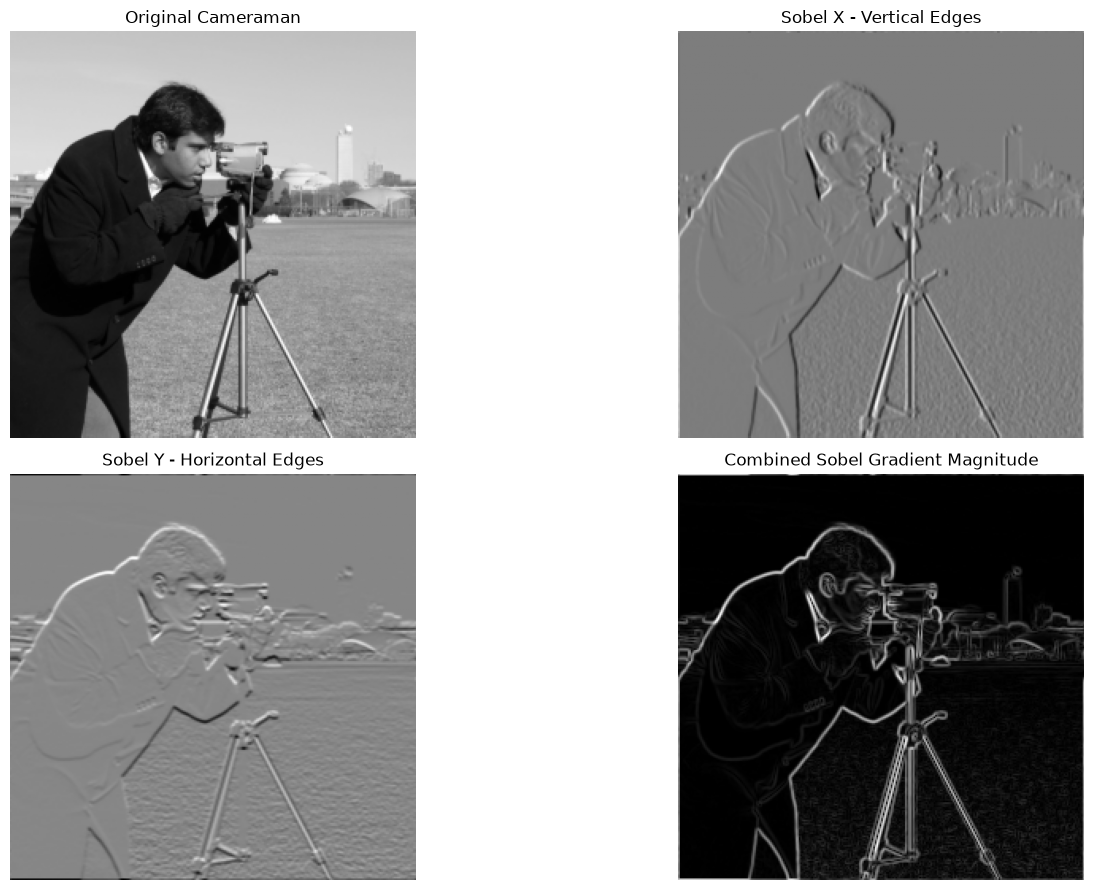

In [10]:
plt.figure(figsize=(16, 9))

plt.subplot(2, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Cameraman")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(sobel_x_image, cmap="gray")
plt.title("Sobel X - Vertical Edges")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(sobel_y_image, cmap="gray")
plt.title("Sobel Y - Horizontal Edges")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(gradient_magnitude, cmap="gray")
plt.title("Combined Sobel Gradient Magnitude")
plt.axis("off")

plt.tight_layout()
plt.show()

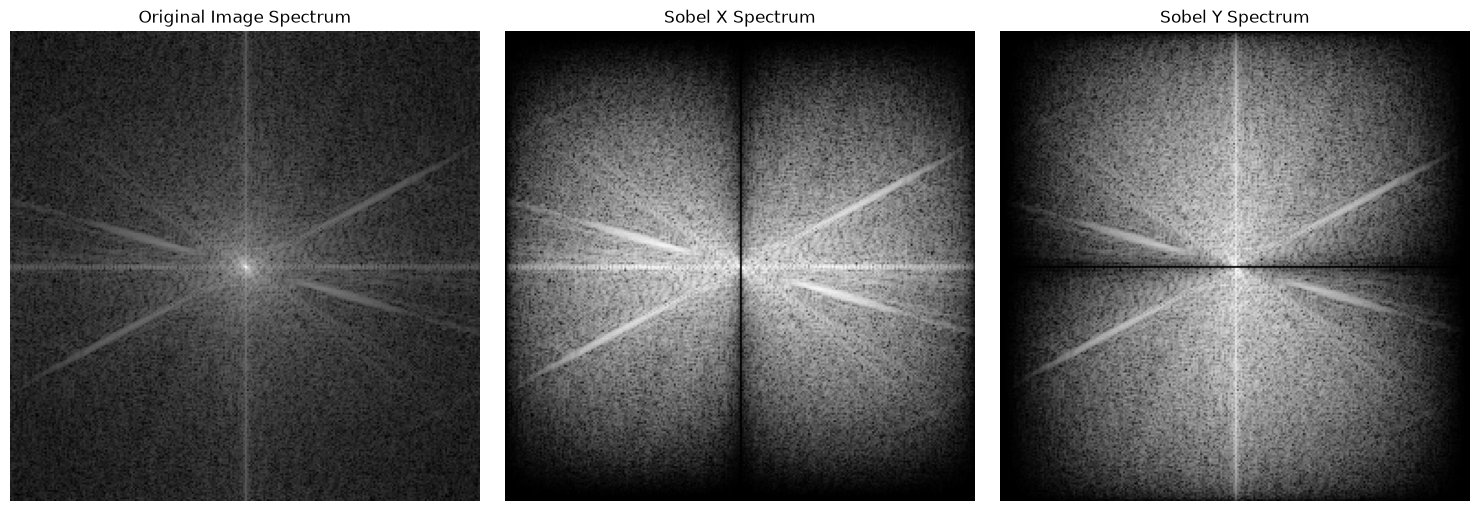

In [11]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(np.log1p(np.abs(np.fft.fftshift(F))), cmap="gray")
plt.title("Original Image Spectrum")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(np.log1p(np.abs(np.fft.fftshift(G_x))), cmap="gray")
plt.title("Sobel X Spectrum")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(np.log1p(np.abs(np.fft.fftshift(G_y))), cmap="gray")
plt.title("Sobel Y Spectrum")
plt.axis("off")

plt.tight_layout()
plt.show()